In [19]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re

sns.set_style('darkgrid')
plt.rcParams.update({
    'lines.linewidth': 2,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
    'axes.labelsize': 14,
    'legend.fontsize': 12,
    'axes.titlesize': 16,
})

In [20]:
val_df = pd.read_csv('/scratch/storage0/ce20b049/Ishita/FineTuning_DDP/Modular/Final/csvs/Validation Accuracy.csv')
train_df = pd.read_csv('/scratch/storage0/ce20b049/Ishita/FineTuning_DDP/Modular/Final/csvs/Training Loss.csv')

In [21]:
# val_ycols = [col for col in val_df.columns if col.endswith('Validation accuracy')]
# train_ycols = [col for col in train_df.columns if col.endswith('Training Loss')]

# print(len(val_ycols))
# print(len(train_ycols))
# print(val_ycols)
# print(train_ycols)

In [22]:
val_ycols = [
    'Num=1,No DP - Validation accuracy',
    'Num=4,No DP - Validation accuracy',
    'Num=16,No DP - Validation accuracy',
    'Num=1,epsilon=32 - Validation accuracy',
    'Num=4,epsilon=32 - Validation accuracy',
    'Num=16,epsilon=32 - Validation accuracy',
    'Num=1,epsilon=8 - Validation accuracy',
    'Num=4,epsilon=8 - Validation accuracy',
    'Num=16,epsilon=8 - Validation accuracy',
    'Num=1,epsilon=2 - Validation accuracy',
    'Num=4,epsilon=2 - Validation accuracy',
    'Num=16,epsilon=2 - Validation accuracy'
]


train_ycols = [
    'Num=1,No DP - Training Loss',
    'Num=4,No DP - Training Loss',
    'Num=1,No DP - Training Loss',
    'Num=1,epsilon=32 - Training Loss',
    'Num=4,epsilon=32 - Training Loss',
    'Num=16,epsilon=32 - Training Loss',
    'Num=1,epsilon=8 - Training Loss',
    'Num=1,epsilon=2 - Training Loss',
    'Num=4,epsilon=8 - Training Loss',
    'Num=4,epsilon=2 - Training Loss',
    'Num=16,epsilon=8 - Training Loss',
    'Num=16,epsilon=2 - Training Loss',
]

In [23]:
val_xcol = 'Epoch'
train_xcol = 'Step'

print(val_xcol)
print(train_xcol)

Epoch
Step


In [24]:
total_steps = train_df['Step'].max()
print(total_steps)
steps_per_epoch = total_steps / 3
print(steps_per_epoch)
train_df['Epoch'] = (train_df['Step'] / steps_per_epoch)
print(train_df['Epoch'])
train_xcol = 'Epoch'

885
295.0
0      0.000000
1      0.003390
2      0.006780
3      0.010169
4      0.013559
         ...   
881    2.986441
882    2.989831
883    2.993220
884    2.996610
885    3.000000
Name: Epoch, Length: 886, dtype: float64


In [25]:
def clean_label(label):
    match = re.search(r'Num=\d+.*?(?:epsilon=\d+|No DP)', label)
    if match:
        clean = match.group(0).replace('Num=', 'n=').replace('epsilon', r'$\epsilon$')
        return clean
    else:
        return label.replace('Num=', 'n=')

print(clean_label('Num=4,epsilon=2 - Validation accuracy'))

n=4,$\epsilon$=2


In [ ]:
import matplotlib.colors as mcolors

base_colors = {
    'No DP': 'dimgray',
    r'$\epsilon$=32': 'tab:red',
    r'$\epsilon$=8': 'tab:blue',
    r'$\epsilon$=2': 'tab:green',
}

intensity_map = {
    'n=16,': 1.0, 
    'n=4,': 0.7, 
    'n=1,': 0.4,  
}


def get_color(label):
    matched_color = None
    matched_intensity = None

    for dp_key in base_colors:
        if dp_key in label:
            matched_color = mcolors.to_rgb(base_colors[dp_key])
            break

    for n_key in intensity_map:
        if n_key in label:
            matched_intensity = intensity_map[n_key]
            break

    if matched_color and matched_intensity is not None:
        # Blend from white (for lightest) to base color (for darkest)
        white = (1.0, 1.0, 1.0)
        return tuple(
            (1 - matched_intensity) * w + matched_intensity * c
            for c, w in zip(matched_color, white)
        )
    else:
        return 'black'


In [ ]:
marker_map = {
    'No DP': '*',             # star
    r'$\epsilon$=2': 'o',     # circle
    r'$\epsilon$=8': 's',     # square
    r'$\epsilon$=32': '^',    # triangle up
}
def get_marker(label):
    for eps_key, marker in marker_map.items():
        if eps_key in label:
            return marker
    return 'x'  


In [33]:
linestyle_map = {
    'No DP': 'solid',          # solid line
    r'$\epsilon$=2': 'dashed', # --
    r'$\epsilon$=8': 'dashdot',# -.
    r'$\epsilon$=32': 'dotted' # :
}
def get_linestyle(label):
    for eps_key, style in linestyle_map.items():
        if eps_key in label:
            return style
    return 'solid'  # fallback

/tmp/ipykernel_3324883/2563587200.py:40: UserWarning: The figure layout has changed to tight
  plt.tight_layout(rect=[0, 0.1, 1, 1])  # Reserve space below for legend


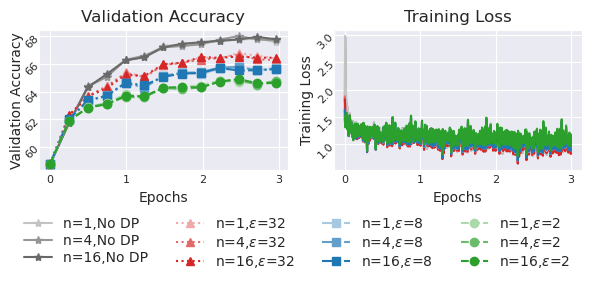

In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(6, 2.5), constrained_layout=True)
all_handles = []
all_labels = []

# Plot Validation Accuracy
for col in val_ycols:
    label=clean_label(col)
    color = get_color(label)
    line, = axs[0].plot(val_df[val_xcol], val_df[col], label=label, linestyle=get_linestyle(label), linewidth=1.5,color=color,marker=get_marker(label))
    all_handles.append(line)
    all_labels.append(clean_label(col))
axs[0].set_xlabel('Epochs', fontsize=10)
axs[0].set_ylabel('Validation Accuracy', fontsize=10)
axs[0].set_xticks([0, 1, 2, 3])
axs[0].tick_params(labelsize=8,pad=-5)
axs[0].set_title('Validation Accuracy', fontsize=12)
axs[0].tick_params(axis='y', labelrotation=45)
axs[0].yaxis.set_label_coords(-0.06, 0.5) 
axs[0].tick_params(axis='x', labelsize=8, pad=0)

# Plot Training Loss
for col in train_ycols:
    label=clean_label(col)
    color = get_color(label)
    line, = axs[1].plot(train_df[train_xcol], train_df[col], label=label, color=color, linewidth=1.5)
    if clean_label(col) not in all_labels:
        all_handles.append(line)
        all_labels.append(clean_label(col))
axs[1].set_xlabel('Epochs', fontsize=10)
axs[1].set_ylabel('Training Loss', fontsize=10)
axs[1].set_xticks([0, 1, 2, 3])
axs[1].set_title('Training Loss', fontsize=12)
axs[1].tick_params(labelsize=8, pad=-5)
axs[1].tick_params(axis='y', labelrotation=45) 
axs[1].yaxis.set_label_coords(-0.08, 0.5) 

axs[1].tick_params(axis='x', labelsize=8, pad=0)

fig.legend(all_handles, all_labels, loc='lower center', ncol=4, bbox_to_anchor=(0.5, -0.15),labelspacing=0.2, frameon=False, fontsize=10)
plt.tight_layout(rect=[0, 0.1, 1, 1]) 

plt.savefig("pdfs_save/loss_accuracy.pdf", format="pdf", bbox_inches="tight", dpi=300)
plt.show()